In [1]:
%pip install pandas numpy scikit-learn gradio flask matplotlib

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [3]:
%pip install gradio flask


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [6]:

import sys
!{sys.executable} -m pip show gradio


Name: gradio
Version: 6.30.0
Summary: Python library for easily interacting with trained machine learning models
Home-page: https://github.com/gradio-app/gradio
Author: 
Author-email: Abubakar Abid <gradio-team@huggingface.co>, Ali Abid <gradio-team@huggingface.co>, Ali Abdalla <gradio-team@huggingface.co>, Dawood Khan <gradio-team@huggingface.co>, Ahsen Khaliq <gradio-team@huggingface.co>, Pete Allen <gradio-team@huggingface.co>, Ömer Faruk Özdemir <gradio-team@huggingface.co>, Freddy A Boulton <gradio-team@huggingface.co>, Hannah Blair <gradio-team@huggingface.co>
License: 
Location: C:\Users\Dell\AppData\Roaming\Python\Python312\site-packages
Requires: anyio, brotli, fastapi, gradio-client, groovy, hf-gradio, httpx, huggingface-hub, jinja2, markupsafe, numpy, orjson, packaging, pandas, pillow, pydantic, pydub, python-multipart, pytz, pyyaml, safehttpx, semantic-version, starlette, tomlkit, typer, typing-extensions, uvicorn
Required-by: 


In [7]:

import sys
print("Python:", sys.executable)

import gradio as gr
print("Gradio version:", gr.__version__)

from flask import Flask, request, render_template_string
print("Flask is working!")


Python: C:\ProgramData\anaconda3\python.exe
Gradio version: 6.30.0
Flask is working!


In [9]:
house_df = pd.read_csv("House price dataset.csv")

house_df.columns = house_df.columns.str.strip().str.lower()

print("Dataset loaded successfully")
print("Dataset shape:", house_df.shape)

display(house_df.head())

Dataset loaded successfully
Dataset shape: (1460, 81)


,id,mssubclass,mszoning,lotfrontage,lotarea,street,alley,lotshape,landcontour,utilities,...,poolarea,poolqc,fence,miscfeature,miscval,mosold,yrsold,saletype,salecondition,saleprice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [10]:
features = ["overallqual", "grlivarea", "garagecars", "totalbsmtsf"]
target = "saleprice"

required_columns = features + [target]
missing_columns = [col for col in required_columns if col not in house_df.columns]

if missing_columns:
    raise ValueError(f"Dataset doesnot find these colomn : {missing_columns}")

for col in required_columns:
    house_df[col] = pd.to_numeric(house_df[col], errors="coerce")

house_df = house_df.dropna(subset=[target]).copy()

X = house_df[features]
y = house_df[target]

print("Missing values before imputation:")
print(X.isnull().sum())

print("\nTarget missing values:", y.isnull().sum())
print("Rows available for training:", len(house_df))


Missing values before imputation:
overallqual    0
grlivarea      0
garagecars     0
totalbsmtsf    0
dtype: int64

Target missing values: 0
Rows available for training: 1460


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20,random_state=42)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])


Training rows: 1168
Testing rows: 292


In [13]:
house_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", LinearRegression())
])

house_model.fit(X_train, y_train)
print("House Price Linear Regression model trained successfully")


House Price Linear Regression model trained successfully


In [14]:
y_pred = house_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("HOUSE PRICE MODEL RESULTS")
print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Mean Squared Error (MSE):  {mse:,.2f}")
print(f"Root Mean Squared Error:   ${rmse:,.2f}")
print(f"R-squared (R²):            {r2:.4f}")

results = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": y_pred.round(2)
})
display(results.head(10))

HOUSE PRICE MODEL RESULTS
Mean Absolute Error (MAE): $25,446.05
Mean Squared Error (MSE):  1,602,914,819.44
Root Mean Squared Error:   $40,036.42
R-squared (R²):            0.7910


,Actual Price,Predicted Price
0,154500,143522.48
1,325000,288596.45
2,115000,136156.55
3,159000,187027.69
4,315500,293501.05
5,75500,45499.09
6,311500,217353.75
7,146000,173893.90
8,84500,45499.09
9,135500,126762.87


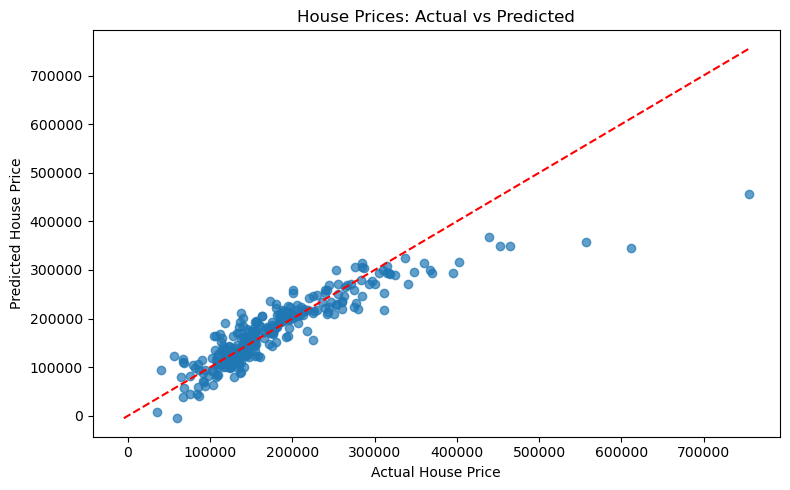

In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("House Prices: Actual vs Predicted")

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--")

plt.tight_layout()
plt.show()


In [14]:
def predict_house(quality, living_area, garage_cars, basement_area):
    values = [quality, living_area, garage_cars, basement_area]

    if any(v is None or not np.isfinite(v) for v in values):
        return "Please enter valid numeric values"

    if not 1 <= quality <= 10:
        return "House quality is b/w 1 to 10 ."

    if living_area <= 0 or garage_cars < 0 or basement_area < 0:
        return "Living area should be positive because garage aur basement does not consider negative value"

    new_house = pd.DataFrame([{
        "overallqual": quality,
        "grlivarea": living_area,
        "garagecars": garage_cars,
        "totalbsmtsf": basement_area
    }])

    predicted_price = house_model.predict(new_house)[0]

    return (
        f"Predicted House Price: ${predicted_price:,.2f}\n"
        f"Model MAE: ${mae:,.2f}\n"
        f"Model RMSE: ${rmse:,.2f}\n"
        f"Model R²: {r2:.4f}"
    )


demo = gr.Interface(
    fn=predict_house,
    inputs=[
        gr.Number(label="Overall Quality (1-10)", value=7),
        gr.Number(label="Living Area (square feet)", value=1500),
        gr.Number(label="Garage Cars", value=2),
        gr.Number(label="Basement Area (square feet)", value=800)
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="House Price Prediction System",
    description="Enter house details to predict its price using Linear Regression."
)

demo.launch()

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


In [17]:
flask_app = Flask("house_price_app")

html_page = """
<!DOCTYPE html>
<html>
<head>
    <title>House Price Prediction</title>
</head>
<body style="font-family: Arial; max-width: 650px; margin: 40px auto;">
    <h1>House Price Prediction System</h1>
    <p>Enter house details below.</p>

    <form method="POST">
        <label>Overall Quality (1-10):</label><br>
        <input type="number" name="quality" min="1" max="10"
               step="1" value="7" required><br><br>

        <label>Living Area (square feet):</label><br>
        <input type="number" name="living_area" min="1"
               step="any" value="1500" required><br><br>

        <label>Garage Cars:</label><br>
        <input type="number" name="garage_cars" min="0"
               step="any" value="2" required><br><br>

        <label>Basement Area (square feet):</label><br>
        <input type="number" name="basement_area" min="0"
               step="any" value="800" required><br><br>

        <button type="submit">Predict Price</button>
    </form>

    {% if result %}
        <h2>Result</h2>
        <pre>{{ result }}</pre>
    {% endif %}
</body>
</html>
"""


@flask_app.route("/", methods=["GET", "POST"])
def home():
    result = ""

    if request.method == "POST":
        try:
            quality = float(request.form["quality"])
            living_area = float(request.form["living_area"])
            garage_cars = float(request.form["garage_cars"])
            basement_area = float(request.form["basement_area"])

            result = predict_house(
                quality, living_area, garage_cars, basement_area
            )

        except (ValueError, TypeError):
            result = "Please enter valid numeric values."

    return render_template_string(html_page, result=result)


print("Flask application created successfully!")


Flask application created successfully!


In [19]:
from werkzeug.serving import make_server
import threading

print("Imports successful!")


Imports successful!


In [20]:
flask_server = make_server("127.0.0.1", 5000, flask_app)

flask_thread = threading.Thread(
    target=flask_server.serve_forever,
    daemon=True
)

flask_thread.start()

print("Flask server started!")
print("Open: http://127.0.0.1:5000")


Flask server started!
Open: http://127.0.0.1:5000


In [22]:

print("Flask app exists:", "flask_app" in globals())
print("Server exists:", "flask_server" in globals())
print("Thread exists:", "flask_thread" in globals())


Flask app exists: True
Server exists: True
Thread exists: True


In [25]:

from werkzeug.serving import make_server
import threading
import time

flask_server = make_server("127.0.0.1", 5000, flask_app)

flask_thread = threading.Thread(
    target=flask_server.serve_forever,
    daemon=True
)
flask_thread.start()

time.sleep(1)

print("Flask server running:", flask_thread.is_alive())
print("Open: http://127.0.0.1:5000")


Flask server running: True
Open: http://127.0.0.1:5000


127.0.0.1 - - [12/Oct/2026 23:19:44] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [12/Oct/2026 23:19:47] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [12/Oct/2026 23:19:52] "POST / HTTP/1.1" 200 -
127.0.0.1 - - [12/Oct/2026 23:19:52] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [12/Oct/2026 23:19:52] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [12/Oct/2026 23:25:43] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [12/Oct/2026 23:25:45] "POST / HTTP/1.1" 200 -


In [26]:

import requests

response = requests.get("http://127.0.0.1:5000", timeout=5)

print("Status code:", response.status_code)
print("Page loaded:", "House Price Prediction System" in response.text)


Status code: 200
Page loaded: True
